# Weeks 3+ — Working with the full release (~79M rows) without downloading 79M rows

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Harjotsingh0311/flyrank-ml-internship/blob/main/notebooks/03_working_with_the_full_release.ipynb?flush_cache=true)

**Local workflow:** Windows / VS Code / uv / Python 3.13. Select the `Python 3.13 (FlyRank ML)` kernel. Colab is also supported if permitted by the dataset terms.

Notebooks 01–02 used the starter CSV. This notebook connects to the gated Parquet warehouse, profiles the unbalanced client panel, builds features in SQL, and evaluates a model on unseen clients. Only aggregate summaries and metrics are displayed. No warehouse data or credentials should be committed.

**Before running:** accept the terms at [FlyRank/internship-warehouse](https://huggingface.co/datasets/FlyRank/internship-warehouse). For local execution, the notebook automatically loads the saved Hugging Face CLI login (including browser/OAuth login) via `huggingface_hub.get_token()`. If necessary, use `hf auth login` in the project's terminal. A Colab secret or a read token entered through a hidden prompt is also supported. Never paste a credential into code or publish it.

**Methodological correction:** the fixed query-level 90-day snapshot overlaps the final outcome window (see `skills/flyrank/flyrank-data/SKILL.md`). We retain the query analysis for description only, not as model inputs. The final-month sample cannot support a 60- or 90-day label. This notebook uses the partitioned daily fact instead.

In [1]:
import os, sys, importlib.util
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "duckdb", "huggingface_hub", "pandas", "numpy", "scikit-learn", "matplotlib"], check=True)
else:
    print("Active interpreter:", sys.executable)
    root = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "requirements.txt").exists() and (p / "notebooks").is_dir()), None)
    if root is not None:
        os.chdir(root)
        expected = root / ".venv" / ("Scripts/python.exe" if os.name == "nt" else "bin/python")
        if expected.exists() and Path(sys.executable).resolve() != expected.resolve():
            raise RuntimeError("Select the project's .venv / FlyRank ML kernel and restart before running.")
    required = ["duckdb", "huggingface_hub", "pandas", "numpy", "sklearn", "matplotlib"]
    missing = [m for m in required if importlib.util.find_spec(m) is None]
    if missing:
        raise RuntimeError(f"Missing {missing}. From the project terminal run: uv pip install -r requirements.txt ipykernel")
    print("Environment ready.")

Active interpreter: c:\workstation\3RD YEAR\flyrank-ml-internship-starter\.venv\Scripts\python.exe
Environment ready.


In [2]:
import getpass
import duckdb
import pandas as pd
import numpy as np
from huggingface_hub import get_token, HfApi

REPO_ID = "FlyRank/internship-warehouse"

def connect_warehouse():
    # get_token() handles HF_TOKEN and the locally cached CLI/OAuth login.
    # In Colab, prefer a notebook secret if no login is available.
    token = get_token()
    if not token and IN_COLAB:
        try:
            from google.colab import userdata
            token = userdata.get("HF_TOKEN")
        except Exception:
            pass
    if not token:
        token = getpass.getpass("Hugging Face READ token (hidden): ")
    token = (token or "").strip()
    if not token:
        raise RuntimeError("No token available. Run hf auth login in the project terminal, then restart the kernel.")

    # Validate through the API, not a prefix check: OAuth tokens may differ.
    api = HfApi(token=token)
    try:
        api.whoami()
    except Exception:
        raise RuntimeError("Hugging Face login could not be verified. Check connectivity and run hf auth whoami; log in again if necessary.") from None
    print("Hugging Face authentication successful.")

    # An in-memory connection and temporary secret keep credentials out of files.
    conn = duckdb.connect(":memory:")
    try:
        conn.execute("INSTALL httpfs")
        conn.execute("LOAD httpfs")
        # Escape SQL string literal characters without displaying the credential.
        conn.execute("CREATE OR REPLACE SECRET hf (TYPE huggingface, TOKEN '" + token.replace("'", "''") + "')")
    except Exception:
        conn.close()
        raise RuntimeError("DuckDB setup failed. Check internet access and the installed DuckDB version. No credential was printed.") from None

    # Metadata alone does not confirm gated file access; read a real small table.
    try:
        count = conn.execute("SELECT COUNT(*) FROM read_parquet('hf://datasets/FlyRank/internship-warehouse/dim_clients.parquet')").fetchone()[0]
    except Exception:
        conn.close()
        raise RuntimeError("Warehouse read failed. Confirm the logged-in account accepted the dataset gate and has permission to read files. If OAuth access is insufficient, create a READ token and log in with it. Check internet access; avoid repeated requests if rate limited.") from None
    print("Gated warehouse read successful; client table rows:", count)
    return conn

# On rerun, close the previous connection before creating a new temporary secret.
if "con" in globals():
    con.close()
con = connect_warehouse()
print("Session-only DuckDB authentication configured.")

Hugging Face authentication successful.
Gated warehouse read successful; client table rows: 104
Session-only DuckDB authentication configured.


## 1. Connect DuckDB to the release

Count the five tables using remote Parquet metadata when possible. The authentication cell has already attempted a gated file read. These counts check access to the remaining tables; it does not establish that all client history is complete. An HTTP 401/403 generally means the token/account or gated access needs attention. For 429, stop and retry later rather than launching repeated full scans.

In [3]:
import pandas as pd
import duckdb

print("DuckDB version:", duckdb.__version__)

# Release any unfinished result from previous cells
if hasattr(con, "abort"):
    con.abort()

REL = "hf://datasets/FlyRank/internship-warehouse"

TABLES = {
    "dim_clients": f"read_parquet('{REL}/dim_clients.parquet')",
    "dim_content": f"read_parquet('{REL}/dim_content.parquet')",
    "fact_daily": f"read_parquet('{REL}/fact_content_daily_performance/**/*.parquet')",
    "fact_daily_sample": f"read_parquet('{REL}/fact_content_daily_performance_sample.parquet')",
    "fact_query_90d": f"read_parquet('{REL}/fact_content_query_90d.parquet')",
}


# Execute queries and consume all results
def run_query(query):
    return con.execute(query).fetchall()


# Verify table row counts
counts = []

for name, src in TABLES.items():
    print(f"Checking {name}...", flush=True)

    count = run_query(
        f"SELECT COUNT(*) FROM {src}"
    )[0][0]

    counts.append((name, count))
    print(f"Rows: {count:,}", flush=True)


# Display warehouse summary
print("\nWarehouse Summary")

summary = pd.DataFrame(
    counts,
    columns=["table", "rows"]
)

print(summary.to_string(index=False))


# Verify date range
start_d, end_d = run_query(f"""
    SELECT MIN(report_date), MAX(report_date)
    FROM {TABLES['fact_daily']}
""")[0]

start_d = pd.Timestamp(start_d).date()
end_d = pd.Timestamp(end_d).date()

print("\nDaily panel dates:", start_d, "to", end_d)
print("Warehouse verification completed successfully.")

DuckDB version: 2.0.1
Checking dim_clients...
Rows: 104
Checking dim_content...
Rows: 519,606
Checking fact_daily...
Rows: 78,835,655
Checking fact_daily_sample...
Rows: 11,694,072
Checking fact_query_90d...
Rows: 2,414,248

Warehouse Summary
            table     rows
      dim_clients      104
      dim_content   519606
       fact_daily 78835655
fact_daily_sample 11694072
   fact_query_90d  2414248

Daily panel dates: 2025-01-27 to 2026-06-30
Warehouse verification completed successfully.


## 2. Know your panel before you model it

Clients have unequal GSC history. We compare history relative to the dataset's final date, not relative to the latest client start date. We use only clients whose recorded GSC start is no later than the start of the relevant feature window. This does not guarantee complete daily reporting.

In [4]:
clients = con.sql(f"SELECT client_hash_id, access_profile, gsc_data_start, ga4_data_start FROM {TABLES['dim_clients']}").df()
gsc_start = pd.to_datetime(clients["gsc_data_start"], errors="coerce")
print("Total clients:", len(clients))
print("Known GSC start:", int(gsc_start.notna().sum()))
print("Clients with at least 365 calendar days since GSC start:", int((gsc_start <= pd.Timestamp(end_d) - pd.Timedelta(days=364)).sum()))
print("Access profile counts:")
print(clients["access_profile"].value_counts(dropna=False).to_string())

Total clients: 104
Known GSC start: 67
Clients with at least 365 calendar days since GSC start: 10
Access profile counts:
access_profile
gsc_and_ga4                             53
no_search_or_analytics_access           26
gsc_only                                14
source_only_missing_client_dimension    10
ga4_only                                 1


## 3. Build features with SQL, not RAM

Use the 90 days ending at the release's final date in one grouped query, then derive the original 60-day exercise and the 90-day extension from the same result. The three non-overlapping 30-day windows are **early**, **previous**, and **outcome**. Predict at the end of the previous window. Only the outcome impressions define the label.

The query uses month partitions intersecting the 90-day window, assuming the release's documented `month=YYYY-MM` layout. It transfers selected columns over the network; it does not download the full warehouse. Keep the full-release result in memory for the remaining cells; avoid repeated scans. Do not substitute the last-month sample for this task.

In [5]:
from datetime import timedelta

cutoff = end_d - timedelta(days=30)
prev_start = end_d - timedelta(days=59)
early_start = end_d - timedelta(days=89)
months = pd.period_range(early_start, end_d, freq="M").astype(str).tolist()
paths = [f"{REL}/fact_content_daily_performance/month={m}/*.parquet" for m in months]
path_list = ", ".join("'" + p + "'" for p in paths)
source = f"read_parquet([{path_list}])"
print("Month partitions:", ", ".join(months))
print("Early:", early_start, "to", prev_start - timedelta(days=1))
print("Previous:", prev_start, "to", cutoff)
print("Outcome:", cutoff + timedelta(days=1), "to", end_d)

# Single per-client/content aggregate; no row-level daily data loaded into pandas.
features = con.sql(f"""
WITH grouped AS (
    SELECT f.client_hash_id, f.content_hash_id,
      SUM(CASE WHEN report_date < DATE '{prev_start}' THEN gsc_impressions END) AS imp_early30,
      SUM(CASE WHEN report_date BETWEEN DATE '{prev_start}' AND DATE '{cutoff}' THEN gsc_impressions END) AS imp_prev30,
      SUM(CASE WHEN report_date > DATE '{cutoff}' THEN gsc_impressions END) AS imp_last30,
      SUM(CASE WHEN report_date BETWEEN DATE '{prev_start}' AND DATE '{cutoff}' THEN gsc_clicks END) AS clk_prev30,
      AVG(CASE WHEN report_date BETWEEN DATE '{prev_start}' AND DATE '{cutoff}' AND gsc_impressions > 0 AND gsc_avg_position > 0 THEN gsc_avg_position END) AS pos_prev30,
      STDDEV_SAMP(CASE WHEN report_date BETWEEN DATE '{prev_start}' AND DATE '{cutoff}' AND gsc_impressions > 0 AND gsc_avg_position > 0 THEN gsc_avg_position END) AS pos_volatility_prev30,
      COUNT(DISTINCT CASE WHEN report_date < DATE '{prev_start}' AND gsc_impressions IS NOT NULL THEN report_date END) AS obs_early30,
      COUNT(DISTINCT CASE WHEN report_date BETWEEN DATE '{prev_start}' AND DATE '{cutoff}' AND gsc_impressions IS NOT NULL THEN report_date END) AS obs_prev30,
      COUNT(DISTINCT CASE WHEN report_date > DATE '{cutoff}' AND gsc_impressions IS NOT NULL THEN report_date END) AS obs_last30
    FROM {source} f
    WHERE report_date BETWEEN DATE '{early_start}' AND DATE '{end_d}'
    GROUP BY 1, 2
    HAVING imp_prev30 >= 100
)
SELECT g.*, c.gsc_data_start
FROM grouped g JOIN {TABLES['dim_clients']} c USING (client_hash_id)
WHERE TRY_CAST(c.gsc_data_start AS DATE) <= DATE '{prev_start}'
""").df()
print("Eligible content items before outcome coverage check:", len(features))
print("Missing outcome observations:", int((features["obs_last30"] == 0).sum()))
print("Duplicate client/content aggregates:", int(features.duplicated(["client_hash_id", "content_hash_id"]).sum()))
assert not features.duplicated(["client_hash_id", "content_hash_id"]).any()

Month partitions: 2026-04, 2026-05, 2026-06
Early: 2026-04-02 to 2026-05-01
Previous: 2026-05-02 to 2026-05-31
Outcome: 2026-06-01 to 2026-06-30
Eligible content items before outcome coverage check: 110501
Missing outcome observations: 0
Duplicate client/content aggregates: 0


## 4. Add query-level signals (descriptive only)

The query table is at client × content × query grain. Use `ANY_VALUE` for repeated context fields, aggregate query impressions, and join on **both** pseudonymous IDs. Query concentration is the largest retained query's share of retained impressions. The fixed 90-day query table overlaps the label window, so the joined columns are **not** eligible predictors here. We show only aggregate summary statistics.

In [6]:
qsignals = con.sql(f"""
SELECT client_hash_id, content_hash_id,
       ANY_VALUE(content_visible_query_count) AS visible_queries,
       ANY_VALUE(rare_impressions_share) AS rare_share,
       ANY_VALUE(anonymized_impressions_share) AS anon_share,
       MAX(impressions_90d) AS top_query_impressions,
       SUM(impressions_90d) AS kept_impressions
FROM {TABLES['fact_query_90d']}
GROUP BY 1, 2
""").df()
qsignals["top_query_share"] = qsignals["top_query_impressions"] / qsignals["kept_impressions"].replace(0, np.nan)
query_summary = features[["client_hash_id", "content_hash_id"]].merge(qsignals, on=["client_hash_id", "content_hash_id"], how="left", validate="one_to_one")
print("Pages matched to visible query counts:", int(query_summary["visible_queries"].notna().sum()))
print(query_summary[["visible_queries", "rare_share", "anon_share", "top_query_share"]].describe().round(3).to_string())
del qsignals, query_summary

Pages matched to visible query counts: 101560
       visible_queries  rare_share  anon_share  top_query_share
count       101560.000  101560.000  101560.000       101560.000
mean            22.832       0.124       0.662            0.392
std             52.979       0.119       0.216            0.257
min              1.000       0.000       0.000            0.003
25%              4.000       0.040       0.550            0.197
50%              9.000       0.086       0.714            0.319
75%             23.000       0.168       0.826            0.520
max           7889.000       0.891       0.996            1.000


## 5. A first model: 60-day window

Label = outcome impressions < 80% of previous-30 impressions. For a first comparison use the source's 100-impression threshold and a pre-outcome feature set. Keep pages with at least one recorded outcome day: missing outcomes are unknown rather than automatically treated as zero. This makes the measured population conditional on outcome availability and is a limitation. Partial reporting may still influence sums.

A random split is a teaching comparator, not the final validation. Use a median-imputation pipeline fit on training data only. Report majority-class accuracy, positive-class prevalence (random ranking expectation), average precision, ROC AUC, balanced accuracy and Precision@50.

In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.metrics import accuracy_score, balanced_accuracy_score, average_precision_score, roc_auc_score, classification_report

base = features.loc[(features["obs_last30"] > 0) & features["imp_last30"].notna()].copy()
base["is_declining"] = (base["imp_last30"] < 0.8 * base["imp_prev30"]).astype(int)
base["ctr_prev30"] = 100 * base["clk_prev30"] / base["imp_prev30"]
base_cols = ["imp_prev30", "ctr_prev30", "pos_prev30"]

def splits(frame, grouped):
    y = frame["is_declining"].to_numpy()
    if len(np.unique(y)) < 2:
        raise ValueError("Both label classes are required.")
    idx = np.arange(len(frame))
    if grouped:
        tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42).split(idx, y, groups=frame["client_hash_id"]))
        assert set(frame.iloc[tr]["client_hash_id"]).isdisjoint(frame.iloc[te]["client_hash_id"])
    else:
        tr, te = train_test_split(idx, test_size=0.25, random_state=42, stratify=y)
    if len(np.unique(y[tr])) < 2 or len(np.unique(y[te])) < 2:
        raise ValueError("Split has only one class; report this limitation before interpreting metrics.")
    return tr, te

def evaluate(frame, cols, tr, te, name):
    X = frame[cols].replace([np.inf, -np.inf], np.nan)
    y = frame["is_declining"].to_numpy()
    estimator = make_pipeline(SimpleImputer(strategy="median", keep_empty_features=True), RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=4))
    estimator.fit(X.iloc[tr], y[tr])
    score = estimator.predict_proba(X.iloc[te])[:, 1]
    pred = estimator.predict(X.iloc[te]); actual = y[te]
    k = min(50, len(te))
    # Stable tie handling for reproducibility; ties at the boundary remain a limitation.
    order = np.argsort(-score, kind="stable")
    train_groups = set(frame.iloc[tr]["client_hash_id"])
    test_groups = set(frame.iloc[te]["client_hash_id"])
    majority_label = int(y[tr].mean() >= 0.5)
    row = {"experiment": name, "train_rows": len(tr), "test_rows": len(te), "test_clients": len(test_groups),
           "overlapping_clients": len(train_groups & test_groups), "positive_rate": actual.mean(),
           "majority_accuracy": (actual == majority_label).mean(), "accuracy": accuracy_score(actual, pred),
           "balanced_accuracy": balanced_accuracy_score(actual, pred), "average_precision": average_precision_score(actual, score),
           "roc_auc": roc_auc_score(actual, score), "precision_at_50": actual[order[:k]].mean(), "k": k}
    return row, estimator, classification_report(actual, pred, digits=3, zero_division=0)

base = base.sort_values(["client_hash_id", "content_hash_id"]).reset_index(drop=True)
tr, te = splits(base, grouped=False)
first, first_model, first_report = evaluate(base, base_cols, tr, te, "60d / random / threshold 100")
print(pd.DataFrame([first]).round(4).to_string(index=False))
print(first_report)

                  experiment  train_rows  test_rows  test_clients  overlapping_clients  positive_rate  majority_accuracy  accuracy  balanced_accuracy  average_precision  roc_auc  precision_at_50  k
60d / random / threshold 100       82875      27626            43                   43         0.6466             0.6466    0.6066              0.544             0.7085   0.5801             0.94 50
              precision    recall  f1-score   support

           0      0.427     0.331     0.373      9763
           1      0.674     0.757     0.713     17863

    accuracy                          0.607     27626
   macro avg      0.551     0.544     0.543     27626
weighted avg      0.587     0.607     0.593     27626



## 6. Your turn — completed experimental design

**Research question:** Does additional pre-outcome history and position volatility help identify pages at risk of an impression decline on unseen clients?

1. Extend the SQL lookback from 60 to 90 days (the three windows were aggregated above in one scan). Use a more conservative previous-window threshold of 200 impressions and require at least one early-window observation plus client history covering all 90 days. The threshold is an exploratory choice, not a validated business cutoff.
2. Add prior momentum (previous vs early impressions) and position volatility calculated **before** the outcome. Compare against the same 60-day features on exactly the same eligible pages and identical grouped split.
3. Compare row-random and client-held-out performance using identical features and cohort. A gap is descriptive, not proof of memorization; different client composition can also explain it.

The final month is used here as the exercise's outcome window, not as a claim of a sealed future test. A later, time-separated evaluation is required for a deployment claim.

In [8]:
cohort = base.loc[(base["imp_prev30"] >= 200) & (base["obs_early30"] > 0) & base["imp_early30"].notna() & (pd.to_datetime(base["gsc_data_start"], errors="coerce") <= pd.Timestamp(early_start))].copy().reset_index(drop=True)
# log1p difference is defined even when earlier impressions are zero.
cohort["prior_log_momentum"] = np.log1p(cohort["imp_prev30"]) - np.log1p(cohort["imp_early30"])
extended_cols = base_cols + ["prior_log_momentum", "pos_volatility_prev30"]
assert not set(extended_cols) & {"imp_last30", "is_declining", "client_hash_id", "content_hash_id", "top_query_share", "visible_queries"}
print("90-day cohort pages:", len(cohort), "| clients:", cohort["client_hash_id"].nunique())
random_tr, random_te = splits(cohort, grouped=False)
group_tr, group_te = splits(cohort, grouped=True)
results = []
models = {}
for name, cols, tr, te in [
    ("60d / grouped", base_cols, group_tr, group_te),
    ("90d / random", extended_cols, random_tr, random_te),
    ("90d / grouped", extended_cols, group_tr, group_te),
]:
    row, fitted, report = evaluate(cohort, cols, tr, te, name)
    results.append(row); models[name] = fitted
comparison = pd.DataFrame(results).set_index("experiment")
print(comparison.round(4).to_string())
print("\nFeature importances (grouped 90-day model; descriptive, not causal):")
importance = pd.Series(models["90d / grouped"].named_steps["randomforestclassifier"].feature_importances_, index=extended_cols).sort_values(ascending=False)
print(importance.round(4).to_string())

90-day cohort pages: 81443 | clients: 41
               train_rows  test_rows  test_clients  overlapping_clients  positive_rate  majority_accuracy  accuracy  balanced_accuracy  average_precision  roc_auc  precision_at_50   k
experiment                                                                                                                                                                             
60d / grouped       70727      10716            11                    0         0.5558             0.5558    0.5566             0.5268             0.6139   0.5638             0.64  50
90d / random        61082      20361            38                   37         0.6665             0.6665    0.6671             0.5640             0.7714   0.6360             1.00  50
90d / grouped       70727      10716            11                    0         0.5558             0.5558    0.5750             0.5382             0.6235   0.5810             0.76  50

Feature importances (grouped 90-day mo

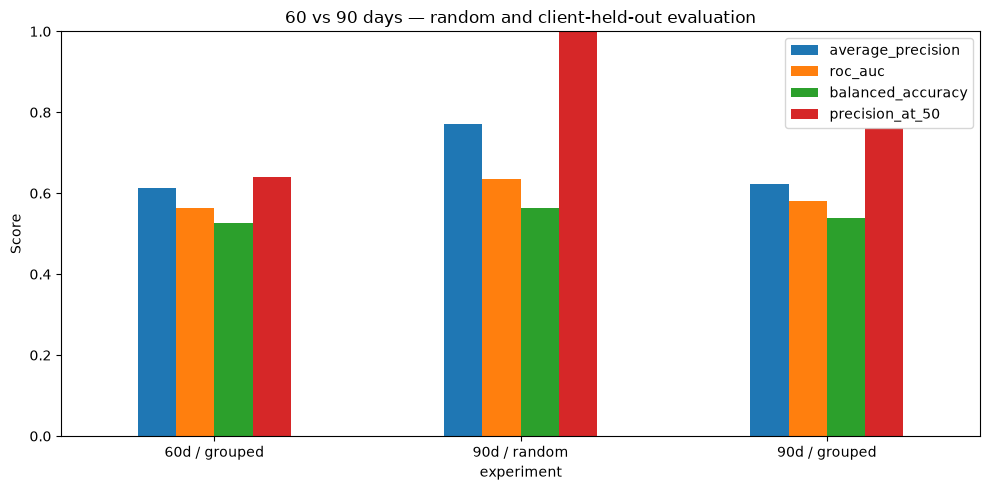

Additional-history change in grouped average precision: +0.0096
Random minus grouped average precision: +0.1478
Observed result: the added features improved average precision on this split
Interpretation: one snapshot and one grouped split; no causal or deployment claim.


In [9]:
import matplotlib.pyplot as plt

comparison[["average_precision", "roc_auc", "balanced_accuracy", "precision_at_50"]].plot.bar(figsize=(10, 5), ylim=(0, 1), rot=0, title="60 vs 90 days — random and client-held-out evaluation")
plt.ylabel("Score")
plt.tight_layout()
plt.show()

gain = comparison.loc["90d / grouped", "average_precision"] - comparison.loc["60d / grouped", "average_precision"]
gap = comparison.loc["90d / random", "average_precision"] - comparison.loc["90d / grouped", "average_precision"]
print(f"Additional-history change in grouped average precision: {gain:+.4f}")
print(f"Random minus grouped average precision: {gap:+.4f}")
print("Observed result:", "the added features improved average precision on this split" if gain > 0 else "the added features did not improve average precision on this split")
print("Interpretation: one snapshot and one grouped split; no causal or deployment claim.")

## 7. Save and review

- All outputs are aggregate counts, statistics, metrics and charts. Do not display raw warehouse rows or IDs, or save the feature frame to the public repository.
- Check the actual runtime results, including the client overlap column (zero for grouped splits) and positive rates. A negative result is valid.
- Query mix is descriptive only because its fixed window overlaps the outcome. Missing/partial reporting and the observed-outcome selection constrain the population. The grouped split does not establish future-period generalization.
- Save the executed notebook with `Ctrl+S`. Before committing, check that no credential or warehouse rows appear in outputs. Submit your repository URL when the portal requests this assignment. Notebook 03 is not necessary for the original Setup assignment.